note: 
* Kiểm tra phân bố dữ liệu: Dữ liệu này thường bị mất cân bằng nghiêm trọng (số giao dịch gian lận Class = 1 rất ít so với giao dịch bình thường Class = 0).

* Tiền xử lý (Preprocessing): Chuẩn hóa cột Amount hoặc Time bằng StandardScaler hoặc MinMaxScaler trước khi đưa vào các mô hình học máy (Machine Learning).

In [2]:
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r"E:\Banking_AI\data\raw_data\creditcard.csv")


In [3]:
#kiem tra gia tri truoc khi standardization
print(df[['Time', 'Amount']].describe())


                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


In [11]:
scaler	= StandardScaler()

df['scaled_amount'] = scaler.fit_transform(df[['Amount']])
df['scaled_time'] = scaler.fit_transform(df[['Time']])

df.drop(['Time', 'Amount'], axis=1, inplace=True)
print(df[['scaled_amount', 'scaled_time']].describe())

       scaled_amount   scaled_time
count   2.848070e+05  2.848070e+05
mean   -3.672378e-17 -5.109395e-17
std     1.000002e+00  1.000002e+00
min    -3.532294e-01 -1.996583e+00
25%    -3.308401e-01 -8.552120e-01
50%    -2.652715e-01 -2.131453e-01
75%    -4.471707e-02  9.372174e-01
max     1.023622e+02  1.642058e+00


C:\Users\khanh\AppData\Local\Temp\ipykernel_16700\1379871940.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['Time', 'Amount'], axis=1, inplace=True)


<Axes: xlabel='scaled_amount'>

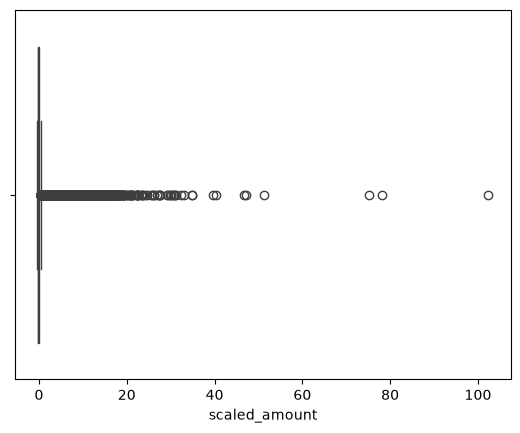

In [12]:
import seaborn as sns

sns.boxplot(x=df['scaled_amount'])

chia x, y train voi test, test tren het 3 mo hinh Random Forest / XGBoost / LightGBM

In [15]:
from sklearn.model_selection import train_test_split
X = df.drop('Class', axis=1)
y =	df['Class']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


* kiểm tra imbalance (mất cân bằng data)

In [17]:
print(y_train.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64


In [18]:
print(
    y_train.value_counts(normalize=True) * 100
)

Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64


* baseline Logistic Regression

In [25]:
weights = [
    {0:1, 1:1},
    {0:1, 1:10},
    {0:1, 1:20},
    {0:1, 1:50},
    {0:1, 1:100}
]

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

for w in weights:

    model = LogisticRegression(
        class_weight=w,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    print(w)
    print(classification_report(y_test, pred))

{0: 1, 1: 1}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962

{0: 1, 1: 10}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.70      0.85      0.76        98

    accuracy                           1.00     56962
   macro avg       0.85      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962

{0: 1, 1: 20}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.61      0.85      0.71        98

    accuracy                           1.00     56962
   macro avg       0.81      0.92      0.86     56962
weighted avg       1.00      1.00

stop lr chuyển sang tiếp theo, save thông số
* Best LR:
* class_weight = {0:1,1:10}
* Precision = 0.70
* Recall = 0.85
* F1 = 0.76

RandomForestClassifier

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



* Random Forest
* n_estimators=200
* class_weight='balanced'

* Precision = 0.92
* Recall    = 0.81
* F1        = 0.86

Next to XG boost

In [39]:
from xgboost import XGBClassifier

scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    tree_method="hist",
    device="cuda",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)


In [40]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    pred_xgb
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



* Random Forest đạt F1-score cao nhất (0.86) và Precision cao nhất (0.92), phù hợp khi cần giảm số lượng cảnh báo sai.

* XGBoost đạt Recall cao hơn (0.84 so với 0.81), phù hợp khi ưu tiên phát hiện nhiều giao dịch gian lận nhất có thể.

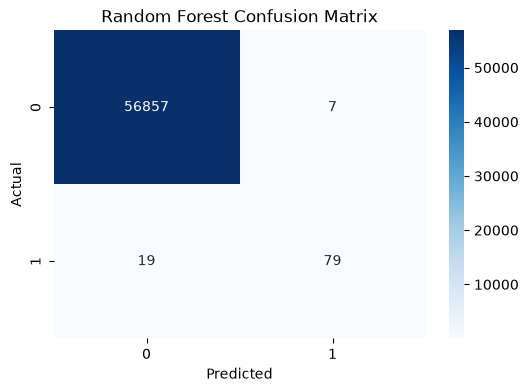

In [41]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_rf)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [42]:
from sklearn.metrics import roc_auc_score

rf_prob = rf.predict_proba(X_test)[:,1]
xgb_prob = xgb.predict_proba(X_test)[:,1]

print("RF:", roc_auc_score(y_test, rf_prob))
print("XGB:", roc_auc_score(y_test, xgb_prob))

RF: 0.9610563837240017
XGB: 0.9727109365130407


In [43]:
from sklearn.metrics import average_precision_score

print("RF PR-AUC:",
      average_precision_score(y_test, rf_prob))

print("XGB PR-AUC:",
      average_precision_score(y_test, xgb_prob))

RF PR-AUC: 0.8618858157934536
XGB PR-AUC: 0.8750727378296564


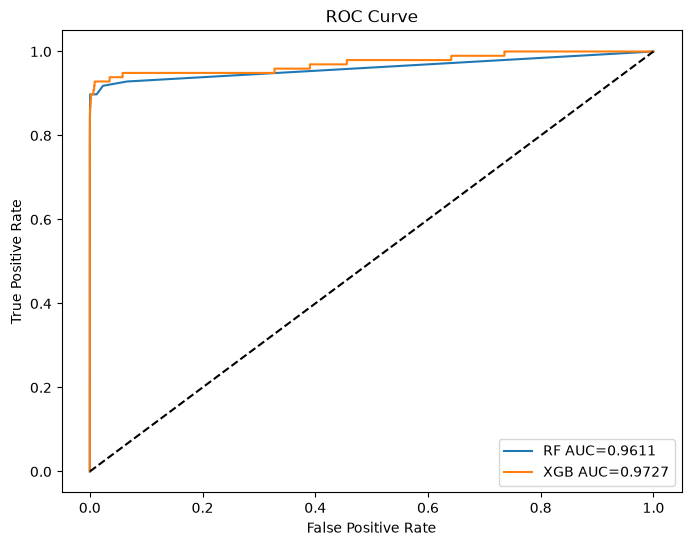

In [44]:
from sklearn.metrics import roc_curve, auc

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'RF AUC={auc(fpr_rf,tpr_rf):.4f}'
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGB AUC={auc(fpr_xgb,tpr_xgb):.4f}'
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# 3. Precision Recall Curve

In [45]:
from sklearn.metrics import precision_recall_curve

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test,
    rf_prob
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    xgb_prob
)

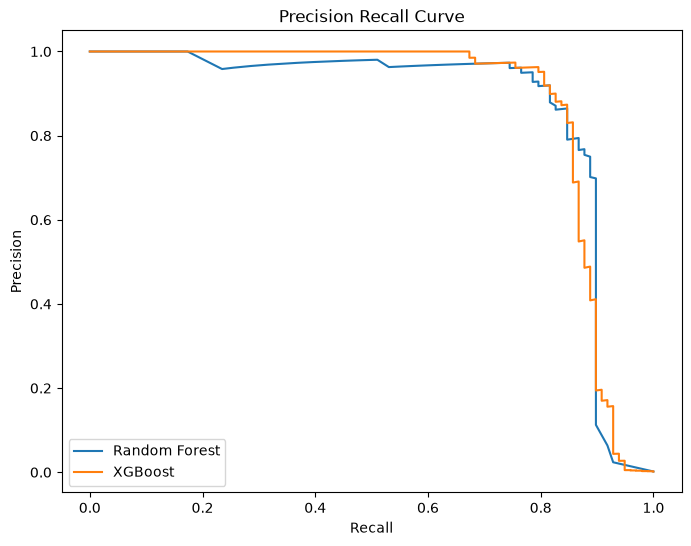

In [46]:
plt.figure(figsize=(8,6))

plt.plot(
    recall_rf,
    precision_rf,
    label='Random Forest'
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label='XGBoost'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision Recall Curve")
plt.legend()

plt.show()


4. Feature Importance

In [47]:
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
).head(10)

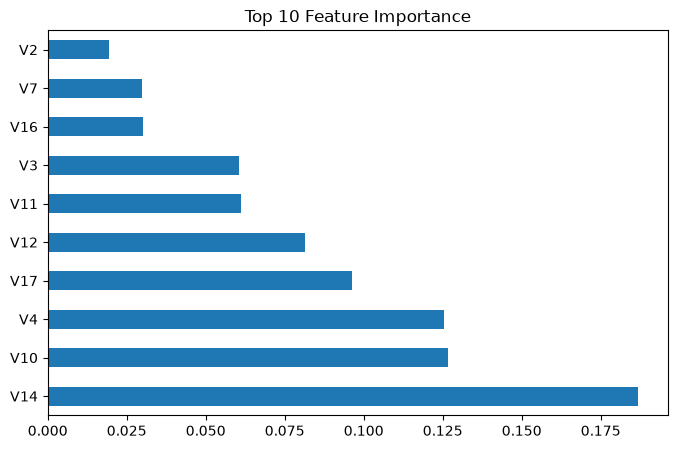

In [48]:
importance.plot(
    kind='barh',
    figsize=(8,5)
)

plt.title("Top 10 Feature Importance")
plt.show()

5. So sánh Model

In [49]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Precision":[0.70,0.92,0.87],
    "Recall":[0.85,0.81,0.84],
    "F1":[0.76,0.86,0.85]
})

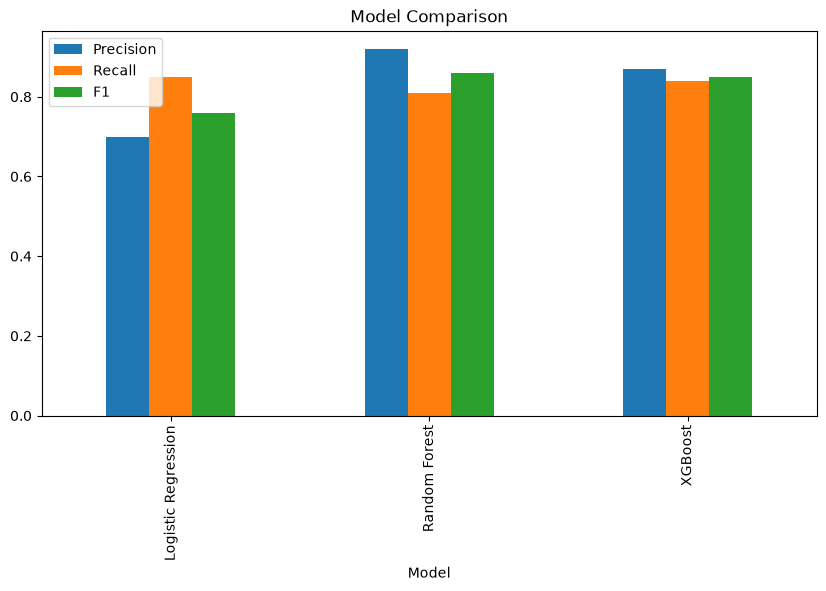

In [50]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Model Comparison")
plt.show()

1. Dataset imbalance analysis

2. Logistic Regression Baseline

3. Class Weight Optimization

4. Random Forest vs XGBoost

5. ROC Curve

6. Precision Recall Curve

7. Feature Importance

8. Business Discussion:
   - Precision hay Recall quan trọng hơn?
   - Chi phí của False Positive / False Negative?

END


In [55]:
df.to_csv(
    r"E:\Banking_AI\data\data_process\creditcard_processed.csv",
    index=False
)


In [56]:
results = {
    "Model": [
        "LogisticRegression",
        "RandomForest",
        "XGBoost"
    ],
    "Precision":[0.70, 0.92, 0.87],
    "Recall":[0.85, 0.81, 0.84],
    "F1":[0.76, 0.86, 0.85]
}

pd.DataFrame(results).to_csv(
    r"E:\Banking_AI\data\data_process\baseline_results.csv",
    index=False
)

In [ ]:
import joblib

joblib.dump(
    rf,
    r"E:\Banking_AI\data\data_process\model_train_package 2\rf_baseline.pkl"
)

['E:\\Banking_AI\\data\\data_process\\rf_baseline.pkl']

In [ ]:
joblib.dump(
    xgb,
    r"E:\Banking_AI\data\data_process\model_train_package 2\xgb_baseline.pkl"
)

['E:\\Banking_AI\\data\\data_process\\xgb_baseline.pkl']